# 1. Preset e Carregamento de Dados (Raw Signal) - Stroop
Importação de bibliotecas base, localização dinâmica da pasta da tarefa Stroop e inspeção inicial do ficheiro `.snirf`.

A ler o ficheiro fNIRS do Stroop:
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\nirs\sub-001_ses-01_tk-stroop_run-1_nirs_001\2026-08-04_001.snirf

Duração da Gravação: 393.12 segundos
Frequência de Amostragem (Hz): 10.17
Triggers encontrados: ['1', '2']

A desenhar topologia da touca 2D...


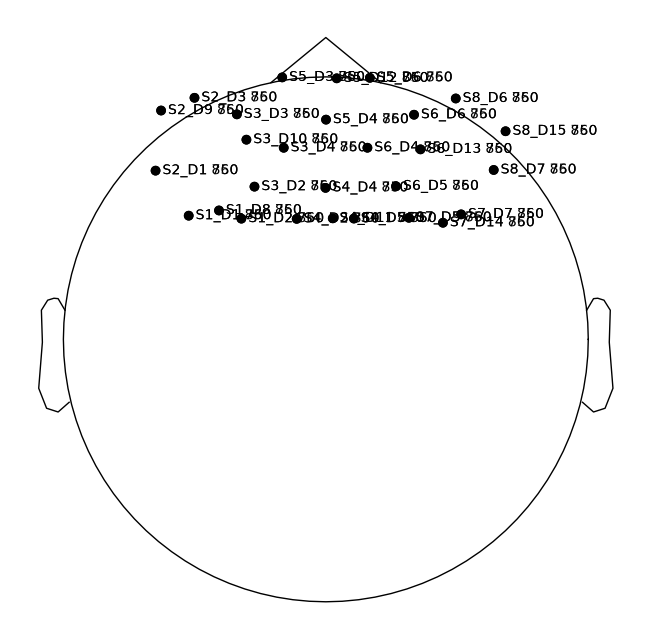

A processar Densidade Ótica (OD)...


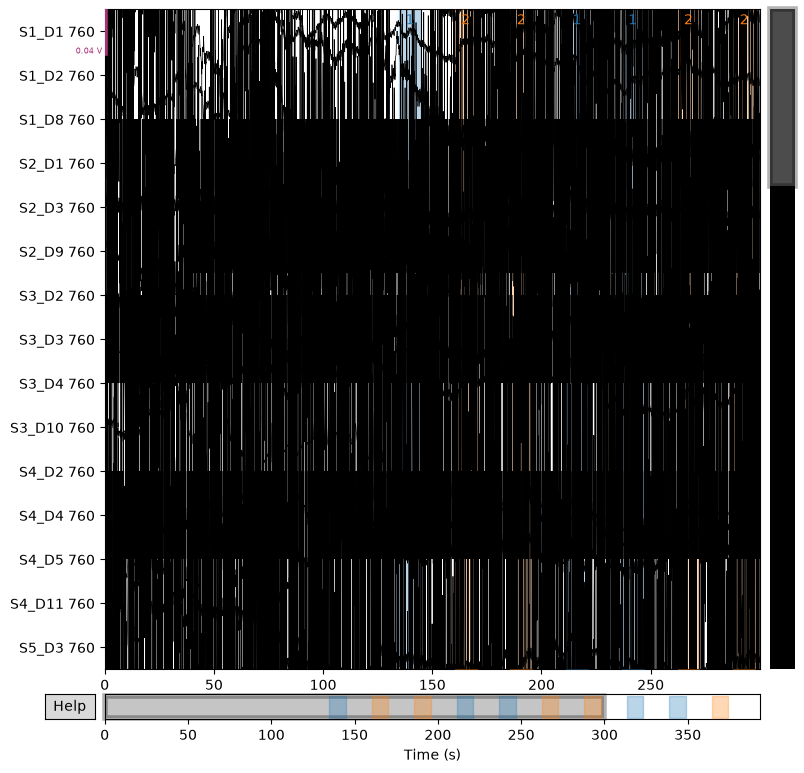

In [4]:
import os
import mne
import mne_nirs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
SUJEITO = "sub-001"
TAREFA = "tk-stroop"

pasta_nirs = os.path.join(BASE_DIR, SUJEITO, "nirs")
nome_pasta_run = next((p for p in os.listdir(pasta_nirs) if TAREFA in p.lower()), None)
pasta_alvo = os.path.join(pasta_nirs, nome_pasta_run)
snirf_file = next((f for f in os.listdir(pasta_alvo) if f.endswith('.snirf')), None)
caminho_snirf = os.path.join(pasta_alvo, snirf_file)

print(f"A ler o ficheiro fNIRS do Stroop:\n{caminho_snirf}")
raw = mne.io.read_raw_snirf(caminho_snirf, preload=True, verbose=False)

print("\n" + "="*50)
print(f"Duração da Gravação: {raw.times[-1]:.2f} segundos")
print(f"Frequência de Amostragem (Hz): {raw.info['sfreq']:.2f}")
triggers = sorted(list(set(raw.annotations.description)))
print(f"Triggers encontrados: {triggers}")
print("="*50)

print("\nA desenhar topologia da touca 2D...")
mne.viz.set_browser_backend('matplotlib')
fig_montagem_2d = raw.plot_sensors(show_names=True)
plt.show()

print("A processar Densidade Ótica (OD)...")
raw_od = mne.preprocessing.nirs.optical_density(raw)
fig_od = raw_od.plot(n_channels=15, duration=300)
plt.show()

# 2. Controlo de Qualidade (SCI) e Correção de Movimento (TDDR)
Verificação do acoplamento ótico, exclusão de canais maus e aplicação do algoritmo de correção de movimento.

A calcular o Scalp Coupling Index (SCI)...


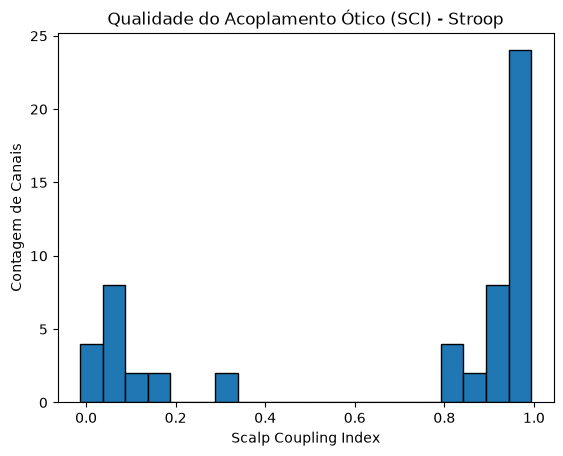

Canais marcados como maus (SCI < 0.7): 18
A aplicar TDDR (Correção de Movimento)...


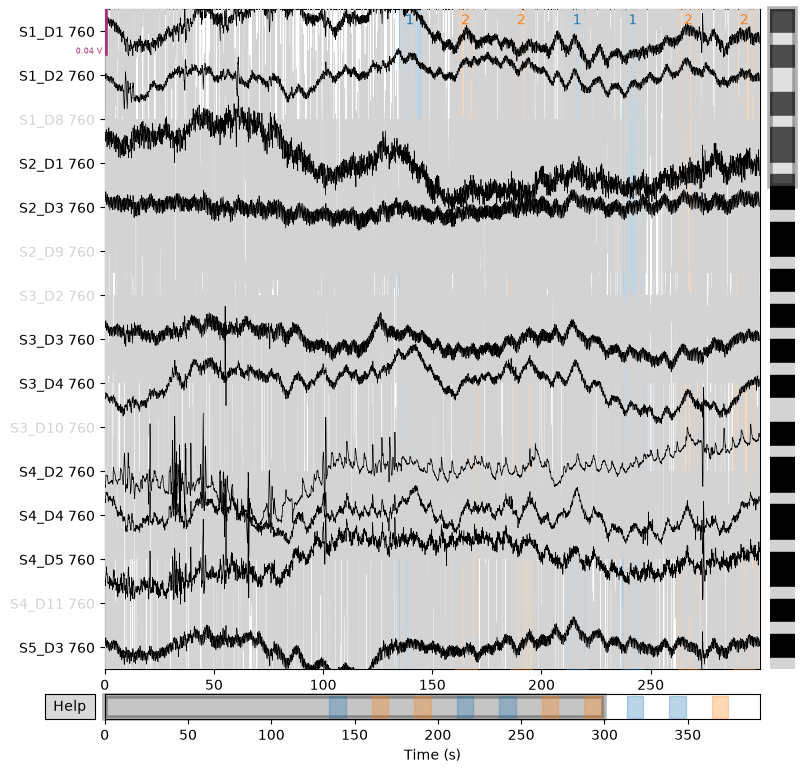

AVISO: Nenhum canal curto com qualidade (SCI >= 0.7) sobreviveu.
A saltar o SSR. O processamento seguirá de forma robusta apenas com TDDR e Filtragem IIR.


In [5]:
LIMIAR_SCI = 0.7
print("A calcular o Scalp Coupling Index (SCI)...")
sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od)

fig_sci, ax = plt.subplots()
ax.hist(sci, bins=20, edgecolor='black')
ax.set(xlabel='Scalp Coupling Index', ylabel='Contagem de Canais', title='Qualidade do Acoplamento Ótico (SCI) - Stroop')
plt.show()

bads_sci = list(np.array(raw_od.ch_names)[sci < LIMIAR_SCI])
raw_od.info['bads'] = bads_sci
print(f"Canais marcados como maus (SCI < {LIMIAR_SCI}): {len(bads_sci)}")

print("A aplicar TDDR (Correção de Movimento)...")
raw_od_tddr = mne.preprocessing.nirs.temporal_derivative_distribution_repair(raw_od)
fig_tddr = raw_od_tddr.plot(n_channels=15, duration=300)
plt.show()

# Verificar Canais Curtos para SSR APENAS nos canais válidos
picks_validos = mne.pick_types(raw_od_tddr.info, fnirs=True, exclude='bads')
distancias = mne.preprocessing.nirs.source_detector_distances(raw_od_tddr.info, picks=picks_validos)
num_curtos_validos = np.sum(distancias <= 0.01)

if num_curtos_validos > 0:
    print(f"Encontrados {num_curtos_validos} canais curtos válidos. A aplicar SSR...")
    raw_od_ssr = mne_nirs.signal_enhancement.short_channel_regression(raw_od_tddr)
else:
    print("AVISO: Nenhum canal curto com qualidade (SCI >= 0.7) sobreviveu.")
    print("A saltar o SSR. O processamento seguirá de forma robusta apenas com TDDR e Filtragem IIR.")
    raw_od_ssr = raw_od_tddr.copy()

# 3. Conversão para Hemoglobina e Segmentação (Epoching)
Conversão mBLL, filtragem IIR e epoching centrado nos blocos Incongruentes ('2').

A converter para HbO e HbR e a aplicar filtro IIR...
A construir as Épocas para o bloco 'Incongruente'...

Ondas Evoked (HbO) para blocos Incongruentes:


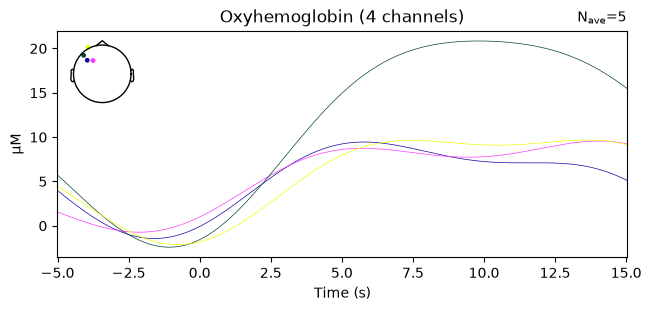


Curva Média Incongruente com Intervalo de Confiança (Canal S1_D1 hbo):


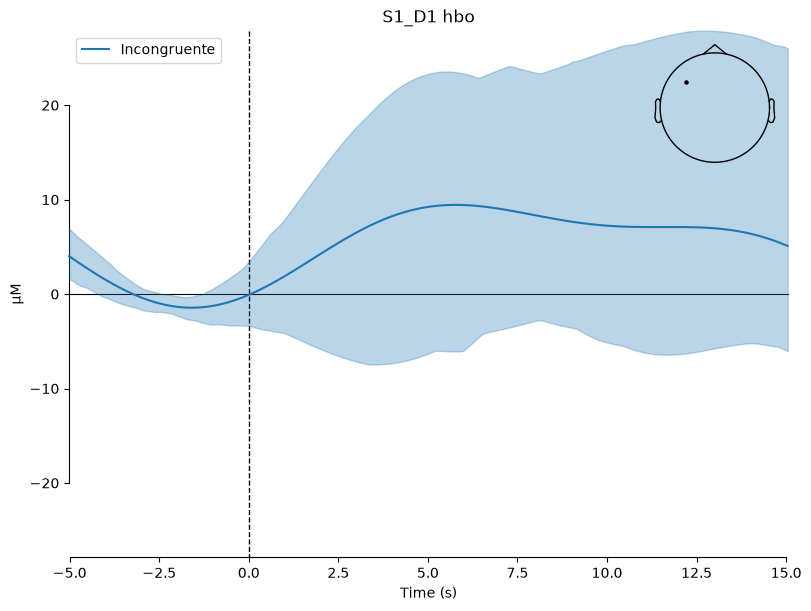

In [6]:
LOW_CUTOFF_HZ, HIGH_CUTOFF_HZ = 0.01, 0.10

print("A converter para HbO e HbR e a aplicar filtro IIR...")
raw_haemo = mne.preprocessing.nirs.beer_lambert_law(raw_od_ssr, ppf=0.1)
raw_filtrado = raw_haemo.filter(LOW_CUTOFF_HZ, HIGH_CUTOFF_HZ, method="iir", verbose=False)

EVENTOS_STROOP = {"1": "Congruente", "2": "Incongruente"}
renomear = {cod: nome for cod, nome in EVENTOS_STROOP.items() if cod in raw_filtrado.annotations.description}
raw_filtrado.annotations.rename(renomear)

events, event_dict = mne.events_from_annotations(raw_filtrado, verbose=False)

# Janela adaptada ao bloco do Stroop (-5s a 15s)
tmin, tmax = -5.0, 15.0
print("A construir as Épocas para o bloco 'Incongruente'...")
epochs = mne.Epochs(raw_filtrado, events, event_id=event_dict, tmin=tmin, tmax=tmax, baseline=(-5.0, 0.0), preload=True, verbose=False)

if 'Incongruente' in epochs.event_id:
    evoked_inc = epochs['Incongruente'].average()
    picks_hbo = mne.pick_types(evoked_inc.info, fnirs='hbo', exclude='bads')
    
    print("\nOndas Evoked (HbO) para blocos Incongruentes:")
    evoked_inc.plot(picks=picks_hbo[:4])
    
    canal_alvo = raw_filtrado.ch_names[picks_hbo[0]]
    evokeds_list = [epochs['Incongruente'][i].average() for i in range(len(epochs['Incongruente']))]
    
    print(f"\nCurva Média Incongruente com Intervalo de Confiança (Canal {canal_alvo}):")
    mne.viz.plot_compare_evokeds({'Incongruente': evokeds_list}, picks=[canal_alvo], ci=True, show_sensors='upper right')
    plt.show()

# 4. GLM e Extração do Contraste (Incongruente - Congruente)
Isolamento cortical, matriz de desenho e cálculo estatístico do conflito cognitivo.

In [7]:
from mne_nirs.experimental_design import make_first_level_design_matrix
from mne_nirs.statistics import run_glm

picks_fnirs = mne.pick_types(raw_filtrado.info, fnirs=True, exclude="bads")
distancias = mne.preprocessing.nirs.source_detector_distances(raw_filtrado.info, picks=picks_fnirs)
picks_longos = picks_fnirs[distancias > 0.015]
raw_cerebral = raw_filtrado.copy().pick(picks_longos)

print("\nA construir a matriz de desenho GLM...")
design_matrix = make_first_level_design_matrix(raw_cerebral, drift_model="cosine", high_pass=LOW_CUTOFF_HZ, hrf_model="glover")
glm_est = run_glm(raw_cerebral, design_matrix)

colunas = design_matrix.columns.tolist()
if "Incongruente" in colunas and "Congruente" in colunas:
    # Contraste Incongruente vs Congruente
    vetor_contraste = np.zeros(len(colunas))
    vetor_contraste[colunas.index("Incongruente")] = 1
    vetor_contraste[colunas.index("Congruente")] = -1
    
    contraste = glm_est.compute_contrast(vetor_contraste)
    df_contraste = contraste.to_dataframe()
    
    print("\nResultados do GLM (Primeiros 10 canais corticais para Incongruente > Congruente):")
    display(df_contraste[df_contraste['Chroma'] == 'hbo'].head(10))
else:
    print("Condições em falta na matriz GLM.")


A construir a matriz de desenho GLM...

Resultados do GLM (Primeiros 10 canais corticais para Incongruente > Congruente):


variable,ContrastType,effect,p_value,stat,z_score,Source,Detector,Chroma,Significant,ch_name
0,t,5.121258e-06,5.410259e-02,1.606673,1.606313,1,1,hbo,False,S1_D1 hbo
2,t,-3.170476e-06,9.485243e-01,-1.631084,-1.630710,1,2,hbo,False,S1_D2 hbo
4,t,1.552152e-05,1.335629e-06,4.701388,4.694602,2,1,hbo,True,S2_D1 hbo
6,t,1.712479e-05,6.331216e-09,5.702483,5.690559,2,3,hbo,True,S2_D3 hbo
8,t,1.868704e-05,2.747797e-10,6.219642,6.204257,3,3,hbo,True,S3_D3 hbo
10,t,8.297988e-06,8.187878e-04,3.151285,3.149130,3,4,hbo,True,S3_D4 hbo
12,t,-3.241126e-06,9.195405e-01,-1.402248,-1.401987,4,2,hbo,False,S4_D2 hbo
14,t,6.807976e-07,3.827488e-01,0.298290,0.298269,4,4,hbo,False,S4_D4 hbo
16,t,-4.845057e-06,9.805086e-01,-2.065049,-2.064368,4,5,hbo,False,S4_D5 hbo
18,t,2.339468e-05,4.105003e-13,7.181092,7.157603,5,3,hbo,True,S5_D3 hbo
